# Identifying EV, heat pump and solar PV customers

Avangrid gave us lists of customers with three technologies: electric vehicles (**EV**), heat pumps (**HP**) and solar panels (**PV**). The EV and HP lists are **random samples of about 25%** of the customers believed to have them, so most EV and HP customers in the data are unlabeled. The goal is to find them from their electricity use.

### Why this needs a special approach

A normal classifier learns from examples of both classes: customers who *do* and who *don't* have an EV. We only have the first kind. Every other customer is **unlabeled**: some have an EV, most don't, and we don't know which. This is called **positive–unlabeled (PU) learning**.

Two facts make it workable here:

1. The labeled customers were chosen **at random** from all customers with the technology. That is the key assumption behind standard PU methods: labeled positives look like a typical positive.
2. We know roughly **what share** were labeled (about 25%), which lets us turn model scores into probabilities and estimate how many customers have each technology.

### Plan for this notebook

1. Build a table of **per-customer features** in DuckDB that capture the physical signature of each technology.
2. **Test the PU methods on PV first.** The Description tab says the PV list is the *full* list of solar customers, so for PV the true answer is known. We hide 75% of the PV labels, as if PV were labeled like EV and HP, and measure how many hidden PV customers each method finds.
3. Use the trained PV model to look at **customers not on the PV list who look like solar**, to check whether the list is really complete.

Applying the tested methods to EV and HP is the next step.

Run from the project folder, the one containing `onedrive-export/`, after notebooks 10–30.

## Setup

`OMP_NUM_THREADS` is set to 1 **before** scikit-learn is imported. On this machine, scikit-learn's gradient-boosting models otherwise start many threads for each small model and slow down dramatically: a run that takes about a minute single-threaded hadn't finished after 10 minutes. Many small models run much faster one thread at a time.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda'

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')

## Per-customer features

Each feature summarises one customer's full year of hourly use in `ami_analysis`, together with the weather and time-of-day variables in `weather_features` from notebook 30. The features are designed around what each technology physically does to a household's load:

**Solar PV.** `hourly_kwh` is never negative, so it appears to measure only electricity drawn **from** the grid. When panels are generating, the home draws less or nothing, so midday use drops, especially in summer.

| Feature | Meaning |
|---|---|
| `summer_midday_zero_share` | Share of Apr–Sep hours from 11 am–3 pm (`hour_ending` 11–15) with use under 0.05 kWh |
| `summer_midday_kwh`, `summer_night_kwh` | Average use at summer midday and at summer night (`hour_ending` 1–6) |
| `summer_midday_night_ratio` | Midday ÷ night use in summer. Low for solar homes; about 1 or higher for others |
| `midday_summer_winter_ratio` | Summer midday ÷ winter midday (Nov–Jan) use. Low for solar, which generates far more in summer |

The night-time features matter because an **empty or seasonal home** also has near-zero midday use, but it is near zero at night too. A solar home is not.

**EV.** A home charger draws a lot of power (often about 7 kW) for a few hours at a time, regardless of the weather.

| Feature | Meaning |
|---|---|
| `share_high_hours` | Share of hours at least 3 kWh above the customer's own usual (median) use for that hour of day |
| `high_sessions` | Number of separate runs of such high hours, a rough count of charging sessions |
| `sharp_rises` | Number of times use jumps by 3 kWh or more from one hour to the next, like a charger switching on |

**Heat pump.** A heat pump uses more electricity the colder it gets.

| Feature | Meaning |
|---|---|
| `heating_slope` | Extra kWh per day for each degree the day's average temperature is below 55°F (fitted on days below 55°F) |
| `cooling_slope` | Extra kWh per day for each degree above 65°F (fitted on days above 65°F). Heat pumps also cool |
| `heating_slope_rel`, `cooling_slope_rel` | The same slopes divided by the customer's usage on mild days (55–65°F), so large and small homes can be compared |
| `winter_summer_ratio` | Average use in Dec–Feb ÷ Jun–Aug |
| `cold_night_ratio` | Night use in the coldest temperature quartile ÷ night use in the third quartile (mild nights) |

**General size and shape.** `mean_kwh`, `p95_kwh` and `max_kwh` measure how much a home uses. `night_share`, `morning_share`, `afternoon_share` and `evening_share` are the average use in each time of day divided by overall average use, which describes the shape of a typical day.

The table is saved to DuckDB as **`customer_features`** so the EV and HP models can reuse it. It takes about 10–15 seconds to build.

In [2]:
FEATURES_SQL = """
CREATE OR REPLACE TABLE customer_features AS
WITH h AS (
    SELECT a.CUSTOMER_NUMBER, a.usage_date, a.hour_ending, a.hourly_kwh,
           w.time_of_day, w.temp, w.temp_quartile,
           month(a.usage_date) AS m
    FROM ami_analysis a JOIN weather_features w USING (usage_date, hour_ending)
),
-- typical usage for each customer and hour of day (baseline for spotting unusual spikes)
hour_base AS (
    SELECT CUSTOMER_NUMBER, hour_ending, median(hourly_kwh) AS base_kwh
    FROM h GROUP BY ALL
),
spikes AS (
    SELECT h.CUSTOMER_NUMBER, h.usage_date, h.hour_ending,
           (h.hourly_kwh - b.base_kwh) >= 3 AS is_high,
           h.hourly_kwh - LAG(h.hourly_kwh) OVER w AS jump
    FROM h JOIN hour_base b USING (CUSTOMER_NUMBER, hour_ending)
    WINDOW w AS (PARTITION BY h.CUSTOMER_NUMBER ORDER BY h.usage_date, h.hour_ending)
),
sessions AS (
    SELECT CUSTOMER_NUMBER, is_high, jump,
           is_high AND NOT COALESCE(LAG(is_high) OVER w, FALSE) AS session_start
    FROM spikes
    WINDOW w AS (PARTITION BY CUSTOMER_NUMBER ORDER BY usage_date, hour_ending)
),
ev AS (
    SELECT CUSTOMER_NUMBER,
           SUM(session_start::INT) AS high_sessions,
           AVG(is_high::INT) AS share_high_hours,
           SUM((jump >= 3)::INT) AS sharp_rises
    FROM sessions GROUP BY 1
),
daily AS (
    SELECT CUSTOMER_NUMBER, usage_date, SUM(hourly_kwh) AS day_kwh, AVG(temp) AS day_temp
    FROM h GROUP BY ALL
),
hp AS (
    SELECT CUSTOMER_NUMBER,
           regr_slope(day_kwh, GREATEST(55 - day_temp, 0)) FILTER (WHERE day_temp < 55) AS heating_slope,
           regr_slope(day_kwh, GREATEST(day_temp - 65, 0)) FILTER (WHERE day_temp > 65) AS cooling_slope,
           AVG(day_kwh) FILTER (WHERE day_temp BETWEEN 55 AND 65) AS mild_day_kwh
    FROM daily GROUP BY 1
),
base AS (
    SELECT CUSTOMER_NUMBER,
           AVG(hourly_kwh) AS mean_kwh,
           quantile_cont(hourly_kwh, 0.95) AS p95_kwh,
           MAX(hourly_kwh) AS max_kwh,
           AVG(hourly_kwh) FILTER (WHERE m IN (12, 1, 2)) / NULLIF(AVG(hourly_kwh) FILTER (WHERE m IN (6, 7, 8)), 0) AS winter_summer_ratio,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night' AND temp_quartile = 1)
             / NULLIF(AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night' AND temp_quartile = 3), 0) AS cold_night_ratio,
           AVG((hourly_kwh < 0.05)::INT) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m BETWEEN 4 AND 9) AS summer_midday_zero_share,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m BETWEEN 4 AND 9) AS summer_midday_kwh,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 1 AND 6 AND m BETWEEN 4 AND 9) AS summer_night_kwh,
           AVG(hourly_kwh) FILTER (WHERE hour_ending BETWEEN 11 AND 15 AND m IN (11, 12, 1)) AS winter_midday_kwh,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'night') / AVG(hourly_kwh) AS night_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'morning') / AVG(hourly_kwh) AS morning_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'afternoon') / AVG(hourly_kwh) AS afternoon_share,
           AVG(hourly_kwh) FILTER (WHERE time_of_day = 'evening') / AVG(hourly_kwh) AS evening_share
    FROM h GROUP BY 1
)
SELECT base.*,
       summer_midday_kwh / NULLIF(summer_night_kwh, 0) AS summer_midday_night_ratio,
       summer_midday_kwh / NULLIF(winter_midday_kwh, 0) AS midday_summer_winter_ratio,
       ev.high_sessions, ev.share_high_hours, ev.sharp_rises,
       hp.heating_slope, hp.cooling_slope, hp.mild_day_kwh,
       hp.heating_slope / NULLIF(hp.mild_day_kwh, 0) AS heating_slope_rel,
       hp.cooling_slope / NULLIF(hp.mild_day_kwh, 0) AS cooling_slope_rel
FROM base JOIN ev USING (CUSTOMER_NUMBER) JOIN hp USING (CUSTOMER_NUMBER)
ORDER BY CUSTOMER_NUMBER;
"""

con.execute(FEATURES_SQL)
features = con.sql('SELECT * FROM customer_features').pl()
FEATURE_COLS = [c for c in features.columns if c != 'CUSTOMER_NUMBER']
print(f'{features.height:,} customers x {len(FEATURE_COLS)} features')
features.head()

25,156 customers x 23 features


CUSTOMER_NUMBER,mean_kwh,p95_kwh,max_kwh,winter_summer_ratio,cold_night_ratio,summer_midday_zero_share,summer_midday_kwh,summer_night_kwh,winter_midday_kwh,night_share,morning_share,afternoon_share,evening_share,summer_midday_night_ratio,midday_summer_winter_ratio,high_sessions,share_high_hours,sharp_rises,heating_slope,cooling_slope,mild_day_kwh,heating_slope_rel,cooling_slope_rel
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,"decimal[38,0]",f64,"decimal[38,0]",f64,f64,f64,f64,f64
3,1.288055,2.8943,7.169,0.670379,0.96344,0.0,1.54799,1.128474,1.184228,0.808678,0.910487,1.187526,1.093135,1.371755,1.307172,76,0.010505,21,0.096903,2.512317,30.754576,0.003151,0.081689
4,0.72233,1.7093,9.332,1.002379,1.537001,0.0,0.770803,0.465522,0.814733,0.680695,0.911258,1.212633,1.195123,1.655783,0.946081,45,0.008335,27,0.260767,1.839753,15.301271,0.017042,0.120235
6,0.479574,1.01315,6.204,1.194282,1.032052,0.0,0.481496,0.396727,0.433702,0.757275,1.037562,1.068447,1.136494,1.213672,1.1102,1,0.007764,0,0.179135,0.838687,11.190368,0.016008,0.074947
10,0.84363,1.95315,4.88,0.653033,1.14177,0.0,0.9438,0.750481,0.716554,0.863452,0.781027,1.166952,1.188444,1.257594,1.317137,59,0.023293,11,0.161208,3.454151,15.436201,0.010443,0.223769
11,0.538879,1.055,2.13,1.130608,1.4939,0.0,0.510385,0.501211,0.494738,0.974817,1.025774,0.973759,1.025627,1.018303,1.031627,0,0.0,0,0.045604,0.391266,9.725208,0.004689,0.040232


## Labels

The EV, HP and PV lists are loaded from the workbook and added to the feature table as true/false columns. Customers missing from `ami_analysis` (numbered 10,001–20,000, dropped as incomplete, or with no meter data) aren't in `customer_features`, so they drop out automatically.

In [3]:
sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')

TECHS = ['EV', 'HP', 'PV']
for tab, customers in sheets.items():
    tech = tab.split()[0]
    features = features.with_columns(
        pl.col('CUSTOMER_NUMBER').is_in(customers['CUSTOMER_NUMBER'].cast(pl.Int32).implode()).alias(tech)
    )

features.select([pl.col(t).sum() for t in TECHS])

EV,HP,PV
u32,u32,u32
134,58,309


## How the labeled groups differ

Before modelling, we check that the features separate the groups. The table shows the **median** of each feature for each labeled group and for customers on none of the lists. Medians are used because several features are skewed.

Customers on more than one list count in each group. "None" still contains unlabeled EV and HP customers, so the real gaps are somewhat larger than shown.

In [4]:
def group_medians(df: pl.DataFrame) -> pl.DataFrame:
    groups = {t: pl.col(t) for t in TECHS} | {'none': ~pl.any_horizontal(TECHS)}
    rows = [
        df.filter(cond).select(pl.lit(name).alias('group'), *[pl.col(c).median() for c in FEATURE_COLS])
        for name, cond in groups.items()
    ]
    return pl.concat(rows).unpivot(index='group').pivot(on='group', index='variable')

with pl.Config(tbl_rows=-1, float_precision=3, tbl_hide_dataframe_shape=True):
    print(group_medians(features))

┌────────────────────────────┬────────┬────────┬────────┬────────┐
│ variable                   ┆ EV     ┆ HP     ┆ PV     ┆ none   │
│ ---                        ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ str                        ┆ f64    ┆ f64    ┆ f64    ┆ f64    │
╞════════════════════════════╪════════╪════════╪════════╪════════╡
│ mean_kwh                   ┆ 1.131  ┆ 1.127  ┆ 0.936  ┆ 0.745  │
│ p95_kwh                    ┆ 2.945  ┆ 2.839  ┆ 2.709  ┆ 1.990  │
│ max_kwh                    ┆ 7.787  ┆ 6.416  ┆ 6.809  ┆ 5.310  │
│ winter_summer_ratio        ┆ 0.990  ┆ 1.257  ┆ 1.524  ┆ 0.911  │
│ cold_night_ratio           ┆ 1.316  ┆ 1.705  ┆ 1.394  ┆ 1.319  │
│ summer_midday_zero_share   ┆ 0.000  ┆ 0.000  ┆ 0.673  ┆ 0.000  │
│ summer_midday_kwh          ┆ 1.015  ┆ 0.953  ┆ 0.199  ┆ 0.751  │
│ summer_night_kwh           ┆ 0.912  ┆ 0.741  ┆ 0.818  ┆ 0.534  │
│ winter_midday_kwh          ┆ 0.995  ┆ 1.301  ┆ 0.805  ┆ 0.754  │
│ night_share                ┆ 0.853  ┆ 0.806  ┆ 1.064  ┆ 0.79

Each technology stands out on the features designed for it:

- **PV** customers have far lower summer midday use relative to night (`summer_midday_night_ratio` about 0.25 vs about 1.3) and are near zero in about two-thirds of summer midday hours.
- **EV** customers have many more sharp rises in use and more high-power hours.
- **HP** customers have a much steeper heating response (`heating_slope`, `cold_night_ratio`) and use more in winter than in summer.

### Customers with almost no usage

188 customers use almost no electricity all year (average under 0.05 kWh per hour); about 40 of them use none at all. Some ratio features can't be calculated for the lowest users because they would divide by zero, so they are left blank (null): between 40 and 94 customers per feature, as the table below shows. The models fill blanks with the median, and these customers will simply score low for every technology. They are listed here so they aren't mistaken for a data error later.

In [5]:
inactive = features.filter(pl.col('mean_kwh') < 0.05)
print(f'{inactive.height} customers average under 0.05 kWh per hour.')
features.select(pl.all().null_count()).unpivot().filter(pl.col('value') > 0)

188 customers average under 0.05 kWh per hour.


variable,value
str,u32
"""winter_summer_ratio""",94
"""cold_night_ratio""",49
"""summer_midday_night_ratio""",50
"""midday_summer_winter_ratio""",53
"""heating_slope_rel""",40
"""cooling_slope_rel""",40


## PU methods

We compare three ways of ranking unlabeled customers by how likely they are to have a technology. All three use only the labeled positives and the unlabeled customers, never confirmed negatives.

**1. Single-feature rule (baseline).** Rank customers by one hand-picked feature. For PV this is `summer_midday_night_ratio`, with lower meaning more solar-like. A model needs to beat this to be worth its complexity.

**2. Elkan–Noto (logistic regression).** Train an ordinary classifier to separate *labeled* from *unlabeled* customers. Because labeled customers are a random sample of the positives, its predicted probability equals c × P(has the technology), where c is the share of positives that are labeled. Dividing by c turns scores into **probabilities of having the technology**, and adding those up estimates **how many** customers have it.

c is estimated as the model's average score on labeled customers, using cross-validated (out-of-fold) predictions. For the PV test we also know the true c, 0.25, so we can see how good the estimate is. Logistic regression is used because its probabilities are generally well calibrated, which this method depends on. Features are first mapped to a normal distribution (`QuantileTransformer`) because many are heavily skewed.

**3. Bagging PU (gradient boosting).** Train many classifiers, each on all labeled positives plus a different **random sample** of unlabeled customers treated as negatives. Each unlabeled customer is scored only by the models that didn't use it in training, and those scores are averaged. A few hidden positives in each sample only mislead each model slightly, and averaging over many samples smooths that out. Gradient boosting can pick up non-linear patterns and interactions that logistic regression can't. The scores are rankings, not probabilities.

In [6]:
def as_matrix(df: pl.DataFrame) -> np.ndarray:
    X = df.select(FEATURE_COLS).to_numpy().astype(float)
    X[~np.isfinite(X)] = np.nan
    return X


def elkan_noto(X: np.ndarray, labeled: np.ndarray, seed: int):
    """Return (probability of being positive, estimated c, labeled-vs-unlabeled score g)."""
    model = make_pipeline(
        SimpleImputer(strategy='median'),
        QuantileTransformer(output_distribution='normal', random_state=seed),
        LogisticRegression(max_iter=3000),
    )
    g = cross_val_predict(
        model, X, labeled, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba'
    )[:, 1]
    c = g[labeled == 1].mean()
    return np.clip(g / c, 0, 1), c, g


def bagging_pu(X: np.ndarray, labeled: np.ndarray, seed: int, n_models: int = 30, neg_ratio: int = 10):
    """Average out-of-bag score for each unlabeled customer (NaN for labeled customers)."""
    rng = np.random.default_rng(seed)
    pos, unl = np.where(labeled == 1)[0], np.where(labeled == 0)[0]
    k = min(len(unl), neg_ratio * len(pos))
    total, count = np.zeros(len(labeled)), np.zeros(len(labeled))
    for b in range(n_models):
        sample = rng.choice(unl, k, replace=False)
        idx = np.r_[pos, sample]
        y = np.r_[np.ones(len(pos)), np.zeros(k)]
        model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=seed * 1000 + b)
        model.fit(X[idx], y)
        out_of_bag = np.setdiff1d(unl, sample)
        total[out_of_bag] += model.predict_proba(X[out_of_bag])[:, 1]
        count[out_of_bag] += 1
    return np.where(count > 0, total / np.maximum(count, 1), np.nan)

## Test on PV: hide 75% of the labels

To mimic the EV and HP situation, each run keeps a **random 25%** of PV customers labeled and treats the other 75% as unlabeled. We then check how well each method finds the hidden PV customers among all the unlabeled ones. The run is repeated 10 times with different random 25% samples, to show how stable the results are.

**Metrics**, calculated on the unlabeled customers only:

- **AUC**: the chance that a randomly chosen hidden PV customer is ranked above a randomly chosen non-PV customer. 1.0 is perfect; 0.5 is random guessing.
- **Precision in the top k**: k is set to the number of hidden PV customers. Of the k highest-ranked customers, this is the share that really are on the PV list. It's the most practical measure: "if we flagged as many customers as there are hidden PV customers, how many would be right?"
- **Estimated total PV** (Elkan–Noto only): the sum of predicted probabilities, using either the estimated c or the known c = 0.25, compared with the true count.

**Caveat:** if the PV list is not actually complete (see the next section), some top-ranked "non-PV" customers may really have solar. In that case these figures *understate* how well the methods work.

This cell takes about 2 minutes.

In [7]:
X = as_matrix(features)
is_pv = features['PV'].to_numpy()
pv_positions = np.where(is_pv)[0]
rule_score = -features['summer_midday_night_ratio'].fill_null(1.0).to_numpy()  # lower ratio = more solar-like

N_REPEATS = 10
LABELED_SHARE = 0.25
results = []

for seed in range(N_REPEATS):
    rng = np.random.default_rng(100 + seed)
    labeled = np.zeros(len(is_pv), dtype=int)
    labeled[rng.choice(pv_positions, round(LABELED_SHARE * len(pv_positions)), replace=False)] = 1

    unlabeled = labeled == 0
    hidden_pv = is_pv[unlabeled]
    k = hidden_pv.sum()

    p_en, c_est, g = elkan_noto(X, labeled, seed)
    p_bag = bagging_pu(X, labeled, seed)

    for method, score in [('Rule: summer midday/night ratio', rule_score),
                          ('Elkan–Noto (logistic regression)', p_en),
                          ('Bagging PU (gradient boosting)', p_bag)]:
        s = score[unlabeled]
        top_k = np.argsort(-s)[:k]
        results.append({
            'repeat': seed,
            'method': method,
            'auc': roc_auc_score(hidden_pv, s),
            'precision_top_k': hidden_pv[top_k].mean(),
            'estimated_c': c_est if method.startswith('Elkan') else None,
            'est_total_estimated_c': p_en.sum() if method.startswith('Elkan') else None,
            'est_total_known_c': np.clip(g / LABELED_SHARE, 0, 1).sum() if method.startswith('Elkan') else None,
        })

results = pl.DataFrame(results)
pv_test_summary = (
    results.group_by('method', maintain_order=True)
    .agg(
        pl.col('auc').mean().round(3).alias('auc_mean'),
        pl.col('auc').std().round(3).alias('auc_sd'),
        pl.col('precision_top_k').mean().round(3).alias('precision_top_k_mean'),
        pl.col('precision_top_k').std().round(3).alias('precision_top_k_sd'),
        pl.col('estimated_c').mean().round(3),
        pl.col('est_total_estimated_c').mean().round(0),
        pl.col('est_total_known_c').mean().round(0),
    )
)
print(f'True PV customers in the analysis data: {is_pv.sum()}; '
      f'labeled in each run: {round(LABELED_SHARE * len(pv_positions))}; hidden: {is_pv.sum() - round(LABELED_SHARE * len(pv_positions))}')
with pl.Config(tbl_cols=-1, tbl_hide_dataframe_shape=True):
    print(pv_test_summary)

True PV customers in the analysis data: 309; labeled in each run: 77; hidden: 232
┌─────────────┬──────────┬────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ method      ┆ auc_mean ┆ auc_sd ┆ precision_ ┆ precision_ ┆ estimated_ ┆ est_total_ ┆ est_total_ │
│ ---         ┆ ---      ┆ ---    ┆ top_k_mean ┆ top_k_sd   ┆ c          ┆ estimated_ ┆ known_c    │
│ str         ┆ f64      ┆ f64    ┆ ---        ┆ ---        ┆ ---        ┆ c          ┆ ---        │
│             ┆          ┆        ┆ f64        ┆ f64        ┆ f64        ┆ ---        ┆ f64        │
│             ┆          ┆        ┆            ┆            ┆            ┆ f64        ┆            │
╞═════════════╪══════════╪════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ Rule:       ┆ 0.936    ┆ 0.007  ┆ 0.655      ┆ 0.009      ┆ null       ┆ null       ┆ null       │
│ summer midd ┆          ┆        ┆            ┆            ┆            ┆            ┆            │
│ ay/nigh

### What the PV test shows

- **Both PU models beat the single-feature rule.** Combining many features finds more hidden solar customers than the best single feature: precision in the top k rises from about 0.66 to 0.77–0.83.
- **Bagging PU is the better ranker.** Its AUC is about the same as Elkan–Noto's, but it puts more true PV customers at the very top of the list (higher precision in the top k), which is what matters when flagging customers. The results barely change between runs (small standard deviations), so they don't hinge on which 25% happened to be labeled.
- **Elkan–Noto's count estimates bracket the truth.** Its estimated c (about 0.18) is lower than the true 0.25, so the total comes out about 11% too high (about 343 vs 309). Using the known c = 0.25 gives a total about 13% too low (about 270). The model's probabilities aren't perfectly calibrated, so neither estimate is exact. For EV and HP, the two together give a **plausible range** rather than a single number.

Overall, the approach works: with only a quarter of solar customers labeled, the models recover most of the rest at high precision. That supports applying the same pipeline to EV and HP, using **bagging PU for ranking** and **Elkan–Noto (estimated and known c) for a range of how many there are**.

## Is the PV list really complete?

Earlier analysis found about 800 customers *not* on the PV list with near-zero use in at least 30% of summer midday hours. That could mean unlisted solar, or homes that are empty or used seasonally.

To check, we train bagging PU on **all** PV labels and score every customer not on the list. A high score means "looks like the PV customers". We then compare these groups:

- **PV list**: all labeled solar customers;
- **Off-list, solar-like**: not on the list, score of at least 0.5;
- **Off-list, low midday use, not solar-like**: near-zero use in at least 30% of summer midday hours, but scoring below 0.5;
- **Everyone else**.

In [8]:
pv_labeled = is_pv.astype(int)
pv_score = bagging_pu(X, pv_labeled, seed=0)
features = features.with_columns(pl.Series('pv_score', pv_score))

off_list = features.filter(~pl.col('PV'))
low_midday = pl.col('summer_midday_zero_share') >= 0.30
print('Off-list customers scoring at least ...')
for t in [0.3, 0.5, 0.7, 0.9]:
    print(f'  {t}: {off_list.filter(pl.col("pv_score") >= t).height}')

lm = off_list.filter(low_midday)
print(f'\nOff-list with near-zero use in >= 30% of summer midday hours: {lm.height}')
print(f'  of which also use < 0.1 kWh at summer night (likely empty or seasonal): '
      f'{lm.filter(pl.col("summer_night_kwh") < 0.1).height}')
print(f'  of which score >= 0.5 (solar-like): {lm.filter(pl.col("pv_score") >= 0.5).height}')

features = features.with_columns(
    pl.when(pl.col('PV')).then(pl.lit('PV list'))
    .when(pl.col('pv_score') >= 0.5).then(pl.lit('Off-list, solar-like (score ≥ 0.5)'))
    .when(low_midday).then(pl.lit('Off-list, low midday use, not solar-like'))
    .otherwise(pl.lit('Everyone else'))
    .alias('pv_check_group')
)
features.group_by('pv_check_group').agg(
    pl.len().alias('customers'),
    pl.col('summer_midday_kwh').median().round(3),
    pl.col('summer_night_kwh').median().round(3),
    pl.col('summer_midday_night_ratio').median().round(3),
    pl.col('midday_summer_winter_ratio').median().round(3),
).sort('customers')

Off-list customers scoring at least ...
  0.3: 103
  0.5: 69
  0.7: 45
  0.9: 26

Off-list with near-zero use in >= 30% of summer midday hours: 788
  of which also use < 0.1 kWh at summer night (likely empty or seasonal): 415
  of which score >= 0.5 (solar-like): 46


pv_check_group,customers,summer_midday_kwh,summer_night_kwh,summer_midday_night_ratio,midday_summer_winter_ratio
str,u32,f64,f64,f64,f64
"""Off-list, solar-like (score ≥ …",69,0.366,0.665,0.425,0.428
"""PV list""",309,0.199,0.818,0.251,0.248
"""Off-list, low midday use, not …",742,0.089,0.085,1.041,0.509
"""Everyone else""",24036,0.773,0.549,1.347,0.994


### Average summer day for each group

The clearest check is to look at the average summer day. The chart shows average use for each hour of the day, Apr–Sep, for each group. Solar homes should dip sharply around midday while using normal amounts in the evening and at night. Empty or seasonal homes should be low all day.

The profiles are calculated in DuckDB over `ami_analysis`.

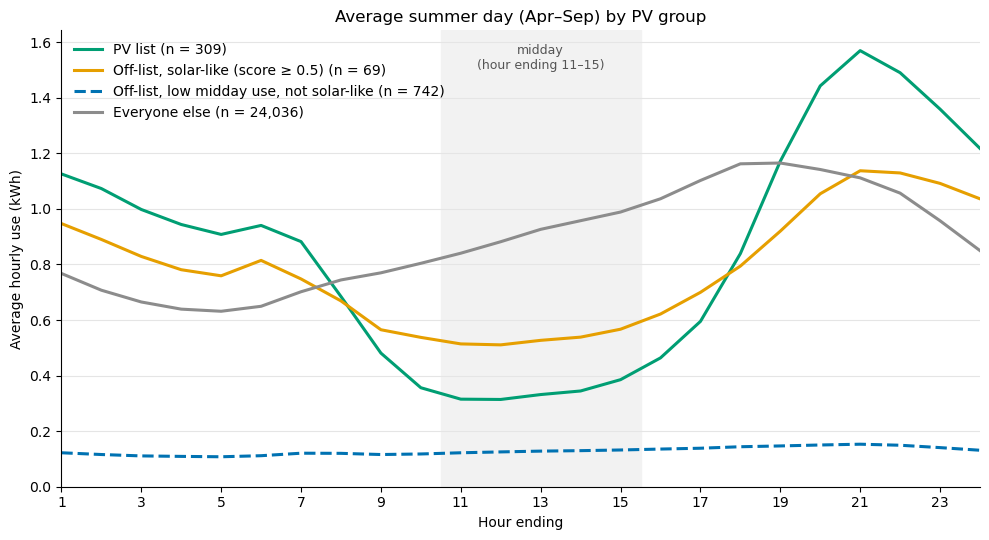

In [9]:
con.register('pv_check_groups', features.select('CUSTOMER_NUMBER', 'pv_check_group'))
profiles = con.sql('''
    SELECT g.pv_check_group, a.hour_ending, AVG(a.hourly_kwh) AS avg_kwh
    FROM ami_analysis a JOIN pv_check_groups g USING (CUSTOMER_NUMBER)
    WHERE month(a.usage_date) BETWEEN 4 AND 9
    GROUP BY ALL ORDER BY ALL
''').pl()

GROUP_STYLE = {
    'PV list': ('#009E73', '-'),
    'Off-list, solar-like (score ≥ 0.5)': ('#E69F00', '-'),
    'Off-list, low midday use, not solar-like': ('#0072B2', '--'),
    'Everyone else': ('#8c8c8c', '-'),
}
counts = dict(features.group_by('pv_check_group').len().iter_rows())

fig, ax = plt.subplots(figsize=(10, 5.5))
for group, (color, style) in GROUP_STYLE.items():
    p = profiles.filter(pl.col('pv_check_group') == group)
    ax.plot(p['hour_ending'], p['avg_kwh'], color=color, linestyle=style, linewidth=2.2,
            label=f'{group} (n = {counts[group]:,})')

ax.axvspan(10.5, 15.5, color='#f2f2f2', zorder=0)
ax.text(13, ax.get_ylim()[1] * 0.97, 'midday\n(hour ending 11–15)', ha='center', va='top', fontsize=9, color='#555555')
ax.set_xticks(range(1, 25, 2))
ax.set_xlim(1, 24)
ax.set_ylim(bottom=0)
ax.set_xlabel('Hour ending')
ax.set_ylabel('Average hourly use (kWh)')
ax.set_title('Average summer day (Apr–Sep) by PV group')
ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/pv_check_summer_profiles.png', dpi=150)
plt.show()

### What this means for the PV list

- Most off-list customers with low midday use are **not** solar. They use little all day, including at night, which suggests empty, seasonal or very low-use homes. The model correctly scores them low, so the features separate "no one home" from "panels generating".
- A smaller group of off-list customers **does** look like solar: a deep midday dip with normal evening use, scoring highly against the PV customers. These may be **unlisted solar customers**, for example installations that are new, not registered, or missed when the list was put together. They're worth raising with Avangrid. Until that's resolved, PV labels should be treated as *nearly* complete rather than perfect.

The candidates are saved below for follow-up.

In [10]:
PV_CANDIDATES_PATH = f'{PLOT_DIR}/pv_offlist_candidates.csv'
pv_candidates = (
    features.filter(pl.col('pv_check_group') == 'Off-list, solar-like (score ≥ 0.5)')
    .select('CUSTOMER_NUMBER', 'pv_score', 'summer_midday_kwh', 'summer_night_kwh',
            'summer_midday_night_ratio', 'midday_summer_winter_ratio', 'summer_midday_zero_share', 'EV', 'HP')
    .sort('pv_score', descending=True)
)
pv_candidates.write_csv(PV_CANDIDATES_PATH)
print(f'Saved {pv_candidates.height} off-list PV candidates to {PV_CANDIDATES_PATH}')
pv_candidates.head(10)

Saved 69 off-list PV candidates to onedrive-export/Data/eda/pv_offlist_candidates.csv


CUSTOMER_NUMBER,pv_score,summer_midday_kwh,summer_night_kwh,summer_midday_night_ratio,midday_summer_winter_ratio,summer_midday_zero_share,EV,HP
i32,f64,f64,f64,f64,f64,f64,bool,bool
33439,0.99993,0.385215,1.565909,0.246001,0.375181,0.612022,false,false
30356,0.999917,0.243603,0.83805,0.290678,0.188466,0.567213,false,false
32034,0.999907,0.027541,0.872357,0.031571,0.123118,0.919126,false,false
33035,0.999865,0.149109,1.258686,0.118464,0.240192,0.808743,false,false
29211,0.999848,0.022819,0.467451,0.048815,0.090783,0.889617,false,false
33430,0.999801,0.258678,1.24305,0.208099,0.078797,0.657923,false,false
35713,0.999758,0.139299,0.77465,0.179822,0.102898,0.659016,false,false
25442,0.999581,0.195867,1.466539,0.133557,0.07798,0.850273,false,false
4960,0.999577,0.209697,0.726324,0.28871,0.337424,0.443716,false,false


## Next steps: EV and HP

The PV test supports this pipeline for EV and HP:

1. **Rank** unlabeled customers with **bagging PU** using all features in `customer_features`.
2. **Estimate how many** have each technology with **Elkan–Noto**, reporting the totals from both the estimated c and the known c ≈ 0.25 as a range. For PV, these bracketed the true count. Compare that range with the rough totals implied by the Description tab (about 560 EV and 280 HP in the analysis data).
3. **Check recall** by hiding some labeled EV and HP customers and seeing where they rank, as done here for PV.
4. **Inspect** the hourly profiles of the top-ranked customers. Charging sessions and heating response are easy to recognise by eye.

Two things to keep in mind: the EV and HP lists are customers Avangrid *believes* have the technology, so some labels may be wrong. Also, other heavy loads (electric resistance heating, pool or well pumps, large homes) can look like EV or HP. Features based on the *shape* of use, not its size, help guard against that.

In [11]:
con.close()